# Importação das Bibliotecas

In [1]:
# Bibliotecas para leitura, manipulação e visualização dos dados
import time
import itertools
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as ctx

from shapely.ops import unary_union
from matplotlib.patches import Patch

# Caminhos dos arquivos no Google Drive
pasta_dados = "./PEmSE"

caminho_area = f"{pasta_dados}/area_interesse.shp"
caminho_passagens = f"{pasta_dados}/passagens_SAR.shp"

# Leitura dos shapefiles
AREAS_INTERESSE = gpd.read_file(caminho_area)
PASSAGENS_SAR = gpd.read_file(caminho_passagens)

# Verifica se os arquivos possuem sistema de coordenadas definido
if AREAS_INTERESSE.crs is None:
    raise ValueError("O shapefile da área de interesse não possui CRS definido.")

if PASSAGENS_SAR.crs is None:
    raise ValueError("O shapefile das passagens SAR não possui CRS definido.")

# Remove geometrias vazias ou nulas
AREAS_INTERESSE = AREAS_INTERESSE[
    AREAS_INTERESSE.geometry.notna() &
    ~AREAS_INTERESSE.geometry.is_empty
].copy()

PASSAGENS_SAR = PASSAGENS_SAR[
    PASSAGENS_SAR.geometry.notna() &
    ~PASSAGENS_SAR.geometry.is_empty
].copy()

# Verifica se ainda existem dados após a limpeza
if AREAS_INTERESSE.empty or PASSAGENS_SAR.empty:
    raise ValueError("Um dos shapefiles não possui geometrias válidas.")

# Reprojeta os dados para um sistema de área equivalente
AREAS_INTERESSE = AREAS_INTERESSE.to_crs("EPSG:6933")
PASSAGENS_SAR = PASSAGENS_SAR.to_crs("EPSG:6933")

print("Áreas de interesse:", len(AREAS_INTERESSE))
print("Passagens SAR disponíveis:", len(PASSAGENS_SAR))
print("CRS utilizado:", PASSAGENS_SAR.crs)

Áreas de interesse: 7
Passagens SAR disponíveis: 702
CRS utilizado: EPSG:6933


# Visualização da Área de Interesse

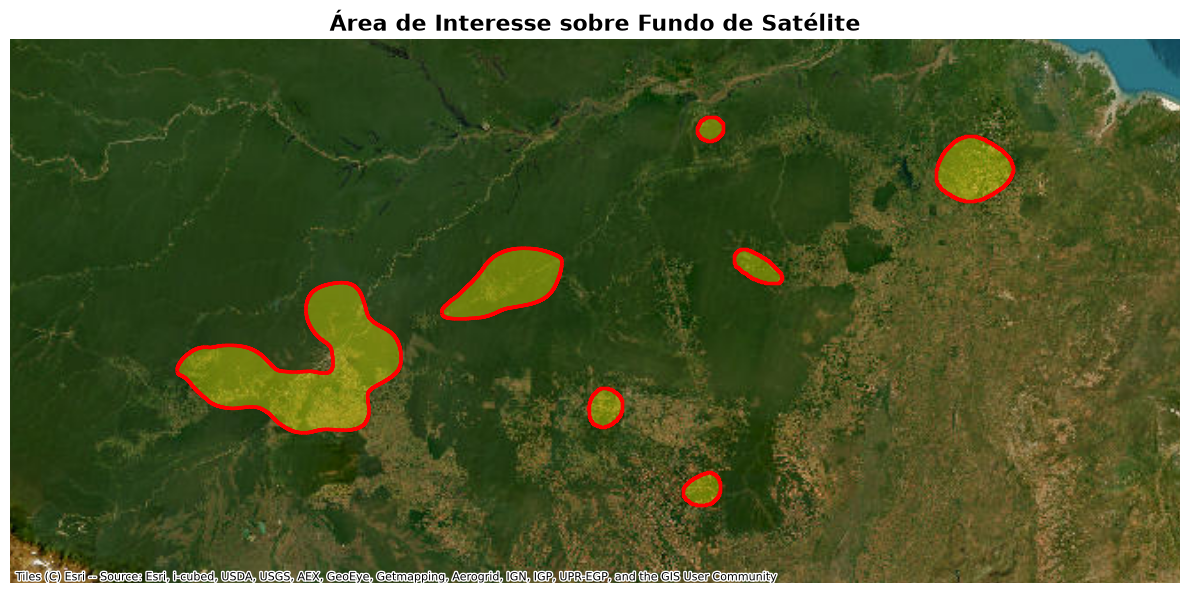

In [2]:
# Reprojeta a área de interesse para o sistema do mapa-base
area_plot = AREAS_INTERESSE.to_crs(epsg=3857)

# Cria a figura
fig, ax = plt.subplots(figsize=(12, 10))

# Obtém os limites espaciais da área de interesse
xmin, ymin, xmax, ymax = area_plot.total_bounds

# Calcula as dimensões da área
dx = xmax - xmin
dy = ymax - ymin

# Adiciona margem de 20% ao redor da área
margem_x = dx * 0.20
margem_y = dy * 0.20

# Define o enquadramento
ax.set_xlim(xmin - margem_x, xmax + margem_x)
ax.set_ylim(ymin - margem_y, ymax + margem_y)

# Adiciona o fundo de satélite
ctx.add_basemap(
    ax,
    source=ctx.providers.Esri.WorldImagery,
    crs=area_plot.crs
)

# Desenha a área de interesse
area_plot.plot(
    ax=ax,
    facecolor="yellow",
    edgecolor="red",
    alpha=0.35,
    linewidth=2.5,
    zorder=2
)

# Destaca o contorno
area_plot.boundary.plot(
    ax=ax,
    color="red",
    linewidth=2.5,
    zorder=3
)

ax.set_title(
    "Área de Interesse sobre Fundo de Satélite",
    fontsize=16,
    fontweight="bold"
)
ax.set_axis_off()
plt.tight_layout()

plt.savefig(
    "area_interesse_amazonia_fundo.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Preparação das Passagens SAR

In [3]:
# Une todas as geometrias da área de interesse em uma única geometria
area_total_geom = unary_union(AREAS_INTERESSE.geometry.tolist())

# Converte a área de metros quadrados para quilômetros quadrados
area_total_km2 = area_total_geom.area / 1_000_000

if area_total_km2 <= 0:
    raise ValueError("A área de interesse possui área nula ou inválida.")

# Lista que armazenará a parte de cada passagem que está dentro da área de interesse
geometrias_recortadas = []

# Lista com a área recortada de cada passagem, em km²
areas_passagens_km2 = []

# Faz o recorte de cada passagem apenas uma vez, antes do PSO
for geometria in PASSAGENS_SAR.geometry:

    # Se a geometria estiver vazia, não há área a considerar
    if geometria is None or geometria.is_empty:
        geometria_recortada = None
    else:
        # Mantém somente a parte da passagem que intersecta a área de interesse
        geometria_recortada = geometria.intersection(area_total_geom)

        # Geometrias sem interseção não contribuem para a cobertura
        if geometria_recortada.is_empty:
            geometria_recortada = None

    geometrias_recortadas.append(geometria_recortada)

    # Calcula a área recortada em km²
    if geometria_recortada is None:
        areas_passagens_km2.append(0.0)
    else:
        areas_passagens_km2.append(geometria_recortada.area / 1_000_000)

# Converte a lista em array para facilitar os cálculos
areas_passagens_km2 = np.asarray(areas_passagens_km2, dtype=float)

# Quantidade de passagens disponíveis após a leitura e limpeza
N_PASSAGENS = len(PASSAGENS_SAR)

print(f"Área de interesse: {area_total_km2:.2f} km²")
print(f"Passagens disponíveis: {N_PASSAGENS}")
print(f"Passagens que intersectam a área: {np.count_nonzero(areas_passagens_km2)}")

Área de interesse: 210259.77 km²
Passagens disponíveis: 702
Passagens que intersectam a área: 702


# Seleção Gulosa para Inicialização e Comparação

In [12]:
def poda_gulosa_reversa(mascara_inicial, alvo_cobertura=0.99, verbose=True):
    """
    Tenta remover passagens redundantes de forma iterativa sem deixar
    a cobertura cair abaixo de `alvo_cobertura`.
    """
    mascara = np.asarray(mascara_inicial, dtype=bool).copy()
    indices_selecionados = list(np.flatnonzero(mascara))
    
    if verbose:
        metricas_originais = calcular_metricas_geometricas(mascara)
        print(f"--- Início da Poda Reversa ---")
        print(f"Passagens iniciais: {len(indices_selecionados)} | "
              f"Cobertura: {metricas_originais['cobertura']*100:.2f}% | "
              f"Sobreposição: {metricas_originais['sobreposicao']*100:.2f}%\n")

    houve_remocao = True
    
    # Itera enquanto for possível remover pelo menos uma passagem por rodada
    while houve_remocao:
        houve_remocao = False
        
        # Avalia a remoção de cada passagem individualmente
        # Ordenamos do índice com menor ganho/área útil para testar os mais fracos primeiro
        for idx in list(indices_selecionados):
            # Cria um conjunto de teste sem a passagem 'idx'
            candidatos_teste = [i for i in indices_selecionados if i != idx]
            
            geometrias_teste = [
                geometrias_recortadas[i]
                for i in candidatos_teste
                if geometrias_recortadas[i] is not None
            ]
            
            # Recalcula a cobertura sem a passagem
            area_uniao_teste = unary_union(geometrias_teste).area / 1_000_000
            cobertura_teste = min(area_uniao_teste / area_total_km2, 1.0)
            
            # Se a cobertura continuar atendendo ao critério, removemos em definitivo
            if cobertura_teste >= alvo_cobertura:
                indices_selecionados.remove(idx)
                mascara[idx] = False
                houve_remocao = True
                
                if verbose:
                    print(f"-> Passagem {idx} removida! "
                          f"Restantes: {len(indices_selecionados)} | "
                          f"Nova Cobertura: {cobertura_teste*100:.3f}%")
                
                # Reinicia a verificação com o novo conjunto reduzido
                break

    metricas_finais = calcular_metricas_geometricas(mascara)
    
    if verbose:
        print(f"\n--- Poda Concluída ---")
        print(f"Passagens finais: {metricas_finais['quantidade']}")
        print(f"Cobertura final: {metricas_finais['cobertura']*100:.2f}%")
        print(f"Sobreposição final: {metricas_finais['sobreposicao']*100:.2f}%")
        
    return mascara, metricas_finais

In [16]:
# Define a meta de cobertura e o limite de passagens.
alvo_cobertura = 0.99
limite_passagens = 40

# Inicia a seleção gulosa usando as geometrias já recortadas.
passagens_selecionadas = []
indices_restantes = [
    i for i, geometria in enumerate(geometrias_recortadas)
    if geometria is not None and not geometria.is_empty
]

cobertura_atual_geom = None
area_coberta_atual = 0.0
cobertura_gulosa = 0.0

inicio_selecao = time.perf_counter()

print("Iniciando a seleção gulosa...", flush=True)

for etapa in range(min(limite_passagens, len(indices_restantes))):

    melhor_indice = None
    maior_ganho = 0.0

    # Procura a passagem que acrescenta mais área ainda não coberta.
    for indice in indices_restantes:

        geometria = geometrias_recortadas[indice]

        if cobertura_atual_geom is None:
            ganho = geometria.area
        else:
            ganho = geometria.difference(cobertura_atual_geom).area

        if ganho > maior_ganho:
            maior_ganho = ganho
            melhor_indice = indice

    # Encerra se nenhuma passagem acrescentar cobertura.
    if melhor_indice is None:
        print("Nenhuma passagem acrescenta cobertura útil.", flush=True)
        break

    passagens_selecionadas.append(melhor_indice)
    indices_restantes.remove(melhor_indice)

    geometria_escolhida = geometrias_recortadas[melhor_indice]

    # Atualiza a geometria coberta.
    if cobertura_atual_geom is None:
        cobertura_atual_geom = geometria_escolhida
    else:
        cobertura_atual_geom = cobertura_atual_geom.union(
            geometria_escolhida
        )

    area_coberta_atual += maior_ganho
    cobertura_gulosa = min((area_coberta_atual / 1_000_000) / area_total_km2, 1.0)

    tempo_decorrido = time.perf_counter() - inicio_selecao

    print(
        f"Passagens: {len(passagens_selecionadas)}/{limite_passagens} | "
        f"Cobertura: {cobertura_gulosa * 100:.2f}% | "
        f"Ganho: {maior_ganho / 1_000_000:.2f} km² | "
        f"Tempo: {tempo_decorrido:.2f}s",
        flush=True
    )

    if cobertura_gulosa >= alvo_cobertura:
        print("Meta de cobertura atingida!", flush=True)
        break

# Recupera as passagens originais selecionadas.
PASSAGENS_OTIMIZADAS = PASSAGENS_SAR.iloc[
    passagens_selecionadas
].copy()

tempo_guloso = time.perf_counter() - inicio_selecao

# Calcula as métricas da solução gulosa.
quantidade_gulosa = len(passagens_selecionadas)
sobreposicao_gulosa = (
    max(0.0, areas_passagens_km2[passagens_selecionadas].sum()
        - area_coberta_atual / 1_000_000)
    / areas_passagens_km2[passagens_selecionadas].sum()
    if quantidade_gulosa > 0
    and areas_passagens_km2[passagens_selecionadas].sum() > 0
    else 0.0
)

# Cria a máscara da solução gulosa para utilizá-la na população inicial do BPSO.
mascara_gulosa = np.zeros(N_PASSAGENS, dtype=int)
mascara_gulosa[passagens_selecionadas] = 1

# Executa a poda reversa sobre a máscara gulosa
mascara_gulosa_otimizada, metricas_gulosa_poda = poda_gulosa_reversa(
    mascara_gulosa,
    alvo_cobertura=0.99
)

# Atualiza a máscara para alimentar a partícula 0 do BPSO
mascara_gulosa = mascara_gulosa_otimizada.astype(int)

print("\nSeleção gulosa concluída!")
print(f"Cobertura: {cobertura_gulosa * 100:.2f}%")
print(f"Passagens selecionadas: {quantidade_gulosa}")
print(f"Sobreposição: {sobreposicao_gulosa * 100:.2f}%")
print(f"Tempo: {tempo_guloso:.2f} segundos")


Iniciando a seleção gulosa...
Passagens: 1/40 | Cobertura: 6.41% | Ganho: 13467.65 km² | Tempo: 0.00s
Passagens: 2/40 | Cobertura: 11.80% | Ganho: 11338.61 km² | Tempo: 0.06s
Passagens: 3/40 | Cobertura: 16.64% | Ganho: 10171.15 km² | Tempo: 0.13s
Passagens: 4/40 | Cobertura: 20.45% | Ganho: 8021.85 km² | Tempo: 0.21s
Passagens: 5/40 | Cobertura: 24.09% | Ganho: 7659.96 km² | Tempo: 0.32s
Passagens: 6/40 | Cobertura: 26.94% | Ganho: 5977.81 km² | Tempo: 0.43s
Passagens: 7/40 | Cobertura: 29.75% | Ganho: 5915.57 km² | Tempo: 0.55s
Passagens: 8/40 | Cobertura: 32.53% | Ganho: 5836.27 km² | Tempo: 0.68s
Passagens: 9/40 | Cobertura: 35.26% | Ganho: 5741.41 km² | Tempo: 0.81s
Passagens: 10/40 | Cobertura: 37.96% | Ganho: 5682.23 km² | Tempo: 0.96s
Passagens: 11/40 | Cobertura: 40.63% | Ganho: 5617.27 km² | Tempo: 1.12s
Passagens: 12/40 | Cobertura: 43.27% | Ganho: 5542.23 km² | Tempo: 1.28s
Passagens: 13/40 | Cobertura: 45.82% | Ganho: 5364.79 km² | Tempo: 1.45s
Passagens: 14/40 | Cobertura

# Função Objetivo

In [4]:
# Cache das métricas geométricas.
# Essas métricas não dependem dos pesos e podem ser reutilizadas.
cache_metricas_geometricas = {}

def calcular_metricas_geometricas(mascara):
    """Calcula cobertura, quantidade e sobreposição de uma solução binária."""

    mascara = np.asarray(mascara, dtype=bool)
    chave = mascara.tobytes()

    if chave in cache_metricas_geometricas:
        return cache_metricas_geometricas[chave]

    indices = np.flatnonzero(mascara)
    quantidade = len(indices)

    if quantidade == 0:
        metricas = {
            "cobertura": 0.0,
            "np": 0.0,
            "sobreposicao": 0.0,
            "quantidade": 0
        }
        cache_metricas_geometricas[chave] = metricas
        return metricas

    geometrias = [
        geometrias_recortadas[i]
        for i in indices
        if geometrias_recortadas[i] is not None
    ]

    soma_areas_km2 = areas_passagens_km2[indices].sum()

    if len(geometrias) == 0 or soma_areas_km2 <= 0:
        area_uniao_km2 = 0.0
    else:
        area_uniao_km2 = unary_union(geometrias).area / 1_000_000

    cobertura = min(area_uniao_km2 / area_total_km2, 1.0)
    np_ratio = quantidade / N_PASSAGENS

    if soma_areas_km2 > 0:
        sobreposicao = max(
            0.0,
            soma_areas_km2 - area_uniao_km2
        ) / soma_areas_km2
    else:
        sobreposicao = 0.0

    metricas = {
        "cobertura": float(cobertura),
        "np": float(np_ratio),
        "sobreposicao": float(sobreposicao),
        "quantidade": int(quantidade)
    }

    cache_metricas_geometricas[chave] = metricas
    return metricas



def avaliar_solucao(mascara, pesos):
    """Calcula o valor da função objetivo para uma solução."""

    metricas = calcular_metricas_geometricas(mascara)

    # Não aceita soluções vazias.
    if metricas["quantidade"] == 0:
        return {"score": -1.0, **metricas}

    w1, w2, w3 = pesos

    # Obtém a quantidade de passagens selecionadas.
    quantidade = metricas["quantidade"]

    # Penalização suave para quantidades acima de 70 passagens.
    penalizacao_passagens = max(0, (quantidade - 20) / 20)

    # Maximiza a cobertura e penaliza a quantidade e a sobreposição.
    score = (
        w1 * metricas["cobertura"]
        - w2 * penalizacao_passagens
        - w3 * metricas["sobreposicao"]
    )

    return {
        "score": float(score),
        **metricas,
        "penalizacao_passagens": float(penalizacao_passagens)
    }

# Implementação do PSO

In [5]:
def sigmoide(velocidade):
    # Converte a velocidade em uma probabilidade entre 0 e 1.
    velocidade = np.clip(velocidade, -10, 10)
    return 1 / (1 + np.exp(-velocidade))


def limitar_passagens(posicao, velocidade, limite):
    # Mantém no máximo o limite permitido de passagens.
    indices_ativos = np.flatnonzero(posicao)

    if len(indices_ativos) <= limite:
        return posicao

    indices_manter = indices_ativos[
        np.argsort(velocidade[indices_ativos])[-limite:]
    ]

    nova_posicao = np.zeros_like(posicao)
    nova_posicao[indices_manter] = 1
    return nova_posicao


def executar_bpso(
    pesos,
    n_particulas=10,
    n_iteracoes=10,
    w_max=0.9,
    w_min=0.4,
    tipo_inercia="linear",
    c1=1.5,
    c2=1.5,
    vmax=4.0,
    limite_passagens_pso=60,
    seed=42
):
    # Inicia o cronómetro e o gerador aleatório
    inicio_execucao = time.perf_counter()
    rng = np.random.default_rng(seed)
    n_dim = N_PASSAGENS

    # Inicializa posições binárias e velocidades aleatórias
    posicoes = np.zeros((n_particulas, n_dim), dtype=int)
    velocidades = rng.uniform(-1, 1, size=(n_particulas, n_dim))

    # Inicialização aleatória simples e independente (sem lógica gulosa)
    for i in range(n_particulas):
        # Sorteia uma quantidade de passagens entre 30 e o limite estipulado
        qtd_inicial = rng.integers(30, max(31, limite_passagens_pso + 1))
        indices_escolhidos = rng.choice(n_dim, size=qtd_inicial, replace=False)
        posicoes[i, indices_escolhidos] = 1

    # Avalia a população inicial e define pbest e gbest
    pbest_posicoes = posicoes.copy()
    pbest_scores = np.array([
        avaliar_solucao(posicoes[i], pesos)["score"]
        for i in range(n_particulas)
    ])

    indice_melhor = np.argmax(pbest_scores)
    gbest_posicao = pbest_posicoes[indice_melhor].copy()
    gbest_score = pbest_scores[indice_melhor]
    historico = [float(gbest_score)]

    # Atualiza o enxame ao longo das iterações
    for iteracao in range(n_iteracoes):

        # Define a inércia conforme a estratégia escolhida
        if tipo_inercia == "constante":
            w = w_max
        elif tipo_inercia == "aleatoria":
            w = rng.uniform(w_min, w_max)
        else:  # inércia linear decrescente
            if n_iteracoes > 1:
                w = w_max - (w_max - w_min) * iteracao / (n_iteracoes - 1)
            else:
                w = w_max

        for i in range(n_particulas):
            r1 = rng.random(n_dim)
            r2 = rng.random(n_dim)

            # Equação de atualização da velocidade: inércia + cognitivo + social
            velocidades[i] = (
                w * velocidades[i]
                + c1 * r1 * (pbest_posicoes[i] - posicoes[i])
                + c2 * r2 * (gbest_posicao - posicoes[i])
            )

            # Aplica os limites inferior e superior da velocidade
            velocidades[i] = np.clip(velocidades[i], -vmax, vmax)

            # BPSO: transforma velocidade em probabilidade e sorteia a posição binária
            probabilidades = sigmoide(velocidades[i])
            nova_posicao = (
                rng.random(n_dim) < probabilidades
            ).astype(int)

            # Evita uma solução vazia
            if nova_posicao.sum() == 0:
                nova_posicao[np.argmax(velocidades[i])] = 1

            # Aplica o limite máximo permitido de passagens
            posicoes[i] = limitar_passagens(nova_posicao, velocidades[i], limite=limite_passagens_pso)

            # Avalia a nova solução usando a função objetivo
            score = avaliar_solucao(posicoes[i], pesos)["score"]

            # Atualiza a melhor solução individual
            if score > pbest_scores[i]:
                pbest_scores[i] = score
                pbest_posicoes[i] = posicoes[i].copy()

                # Atualiza a melhor solução global
                if score > gbest_score:
                    gbest_score = score
                    gbest_posicao = posicoes[i].copy()

        historico.append(float(gbest_score))

        metricas = avaliar_solucao(gbest_posicao, pesos)
        print(
            f"Iteração {iteracao + 1:02d}/{n_iteracoes:02d} | "
            f"Score: {gbest_score:.4f} | "
            f"Cobertura: {metricas['cobertura'] * 100:.2f}% | "
            f"Passagens: {metricas['quantidade']} | "
            f"Sobreposição: {metricas['sobreposicao'] * 100:.2f}%",
            flush=True
        )

    metricas_finais = avaliar_solucao(gbest_posicao, pesos)

    return {
        "melhor_mascara": gbest_posicao.copy(),
        "melhor_score": float(gbest_score),
        "historico": historico,
        "tempo_segundos": time.perf_counter() - inicio_execucao,
        **metricas_finais
    }

# Configuração dos Pesos

In [6]:

# Cada linha representa uma combinação de pesos da função objetivo.
configuracoes_pesos = [
    {"nome": "Prioridade na cobertura", "pesos": (50.0, 0.05, 0.05)},
    {"nome": "Equilibrada", "pesos": (30.0, 0.10, 0.10)},
    {"nome": "Prioridade na sobreposição", "pesos": (30.0, 0.05, 0.50)},
    {"nome": "Prioridade em menos passagens", "pesos": (30.0, 0.50, 0.10)},
    {"nome": "Cobertura e sobreposição", "pesos": (50.0, 0.05, 0.50)},
    {"nome": "Cobertura e quantidade", "pesos": (50.0, 0.50, 0.05)}
]

# Hiperparâmetros fixos para comparar os pesos.
parametros_base = {
    "n_particulas": 5,
    "n_iteracoes": 5,
    "w_max": 0.9,
    "w_min": 0.4,
    "tipo_inercia": "linear",
    "c1": 1.5,
    "c2": 1.5,
    "vmax": 4.0
}

resultados_pesos = []

# Executa cada configuração de pesos.
for i, config in enumerate(configuracoes_pesos, start=1):

    # Usa uma semente diferente em cada experimento.
    seed_experimento = 42 + i

    print(
        f"\n{'=' * 55}\n"
        f"Experimento {i}/{len(configuracoes_pesos)}: {config['nome']}\n"
        f"Pesos: {config['pesos']}\n"
        f"Semente: {seed_experimento}\n"
        f"{'=' * 55}",
        flush=True
    )

    inicio = time.perf_counter()

    # Executa o BPSO.
    resultado = executar_bpso(
        pesos=config["pesos"],
        seed=seed_experimento,
        **parametros_base
    )

    tempo = time.perf_counter() - inicio

    # Exibe os resultados do experimento.
    print(
        f"\nResultado do experimento {i}:\n"
        f"Score: {resultado['melhor_score']:.4f}\n"
        f"Cobertura: {resultado['cobertura'] * 100:.2f}%\n"
        f"Passagens: {resultado['quantidade']}\n"
        f"Sobreposição: {resultado['sobreposicao'] * 100:.2f}%\n"
        f"Tempo: {tempo:.2f} segundos",
        flush=True
    )

    # Armazena os resultados.
    resultados_pesos.append({
        "experimento": config["nome"],
        "seed": seed_experimento,
        "w1_cobertura": config["pesos"][0],
        "w2_passagens": config["pesos"][1],
        "w3_sobreposicao": config["pesos"][2],
        "score": resultado["melhor_score"],
        "cobertura_pct": resultado["cobertura"] * 100,
        "passagens": resultado["quantidade"],
        "sobreposicao_pct": resultado["sobreposicao"] * 100,
        "tempo_segundos": tempo,
        "mascara": resultado["melhor_mascara"],
        "historico": resultado["historico"]
    })

    # Salva os resultados após cada experimento.
    pd.DataFrame(resultados_pesos).to_pickle(
        "resultados_experimento_pesos.pkl"
    )

# Organiza os resultados em uma tabela.
df_pesos = pd.DataFrame(resultados_pesos)

# Exibe os resultados sem comparar scores de escalas diferentes.
display(
    df_pesos[
        [
            "experimento",
            "seed",
            "w1_cobertura",
            "w2_passagens",
            "w3_sobreposicao",
            "cobertura_pct",
            "passagens",
            "sobreposicao_pct",
            "tempo_segundos",
            "score"
        ]
    ].sort_values(
        "cobertura_pct",
        ascending=False
    ).reset_index(drop=True)
)

# Salva os resultados finais.
df_pesos.to_pickle("resultados_experimento_pesos.pkl")

print("\nTodos os experimentos foram concluídos!", flush=True)



Experimento 1/6: Prioridade na cobertura
Pesos: (50.0, 0.05, 0.05)
Semente: 43
Iteração 01/05 | Score: 36.5325 | Cobertura: 73.30% | Passagens: 60 | Sobreposição: 38.23%
Iteração 02/05 | Score: 36.5325 | Cobertura: 73.30% | Passagens: 60 | Sobreposição: 38.23%
Iteração 03/05 | Score: 37.6911 | Cobertura: 75.62% | Passagens: 60 | Sobreposição: 36.29%
Iteração 04/05 | Score: 37.6911 | Cobertura: 75.62% | Passagens: 60 | Sobreposição: 36.29%
Iteração 05/05 | Score: 37.6911 | Cobertura: 75.62% | Passagens: 60 | Sobreposição: 36.29%

Resultado do experimento 1:
Score: 37.6911
Cobertura: 75.62%
Passagens: 60
Sobreposição: 36.29%
Tempo: 0.79 segundos

Experimento 2/6: Equilibrada
Pesos: (30.0, 0.1, 0.1)
Semente: 44
Iteração 01/05 | Score: 20.4401 | Cobertura: 68.93% | Passagens: 60 | Sobreposição: 39.17%
Iteração 02/05 | Score: 20.4401 | Cobertura: 68.93% | Passagens: 60 | Sobreposição: 39.17%
Iteração 03/05 | Score: 22.2762 | Cobertura: 75.06% | Passagens: 60 | Sobreposição: 41.10%
Iteração

,experimento,seed,w1_cobertura,w2_passagens,w3_sobreposicao,cobertura_pct,passagens,sobreposicao_pct,tempo_segundos,score
0,Cobertura e sobreposição,47,50.0,0.05,0.50,77.615190,60,37.072273,0.778143,38.522234
1,Prioridade em menos passagens,46,30.0,0.50,0.10,76.692174,60,38.262240,0.839305,21.969390
2,Equilibrada,44,30.0,0.10,0.10,76.167422,60,40.251682,0.806738,22.609975
3,Prioridade na sobreposição,45,30.0,0.05,0.50,76.153887,60,39.287769,0.809573,22.549727
4,Prioridade na cobertura,43,50.0,0.05,0.05,75.618574,60,36.289434,0.794436,37.691142
5,Cobertura e quantidade,48,50.0,0.50,0.05,74.598907,60,36.607525,0.795621,36.281150



Todos os experimentos foram concluídos!


# Configuração dos Hiperparâmetros

In [8]:
# Pesos fixos: usamos a configuração equilibrada para comparar o algoritmo.
PESOS_BASE = (30.0, 0.10, 0.10)

# Configurações representativas para comparar inércia e coeficientes.
configuracoes_algoritmo = [
    {"nome": "Inércia constante 0.7", "n_particulas": 10, "n_iteracoes": 10,
     "tipo_inercia": "constante", "w_max": 0.7, "w_min": 0.7,
     "c1": 1.5, "c2": 1.5, "vmax": 4.0},
    {"nome": "Inércia linear 0.9-0.4", "n_particulas": 10, "n_iteracoes": 10,
     "tipo_inercia": "linear", "w_max": 0.9, "w_min": 0.4,
     "c1": 1.5, "c2": 1.5, "vmax": 4.0},
    {"nome": "Inércia linear 0.8-0.2", "n_particulas": 10, "n_iteracoes": 10,
     "tipo_inercia": "linear", "w_max": 0.8, "w_min": 0.2,
     "c1": 1.5, "c2": 1.5, "vmax": 4.0},
    {"nome": "Inércia aleatória 0.9-0.4", "n_particulas": 10, "n_iteracoes": 10,
     "tipo_inercia": "aleatoria", "w_max": 0.9, "w_min": 0.4,
     "c1": 1.5, "c2": 1.5, "vmax": 4.0},
    {"nome": "Cognitivo e social 2.0", "n_particulas": 10, "n_iteracoes": 10,
     "tipo_inercia": "linear", "w_max": 0.9, "w_min": 0.4,
     "c1": 2.0, "c2": 2.0, "vmax": 4.0},
    {"nome": "Maior componente cognitiva", "n_particulas": 10, "n_iteracoes": 10,
     "tipo_inercia": "linear", "w_max": 0.9, "w_min": 0.4,
     "c1": 2.5, "c2": 1.5, "vmax": 4.0},
    {"nome": "Maior componente social", "n_particulas": 10, "n_iteracoes": 10,
     "tipo_inercia": "linear", "w_max": 0.9, "w_min": 0.4,
     "c1": 1.5, "c2": 2.5, "vmax": 4.0},
    {"nome": "População 20", "n_particulas": 20, "n_iteracoes": 10,
     "tipo_inercia": "linear", "w_max": 0.9, "w_min": 0.4,
     "c1": 1.5, "c2": 1.5, "vmax": 4.0},
    {"nome": "Mais iterações 20", "n_particulas": 10, "n_iteracoes": 20,
     "tipo_inercia": "linear", "w_max": 0.9, "w_min": 0.4,
     "c1": 1.5, "c2": 1.5, "vmax": 4.0},
    {"nome": "Vmax 2", "n_particulas": 10, "n_iteracoes": 10,
     "tipo_inercia": "linear", "w_max": 0.9, "w_min": 0.4,
     "c1": 1.5, "c2": 1.5, "vmax": 2.0},
    {"nome": "Vmax 6", "n_particulas": 10, "n_iteracoes": 10,
     "tipo_inercia": "linear", "w_max": 0.9, "w_min": 0.4,
     "c1": 1.5, "c2": 1.5, "vmax": 6.0}
]

resultados_bpso = []

for i, config in enumerate(configuracoes_algoritmo, start=1):
    print(f"\nConfiguração BPSO {i}/{len(configuracoes_algoritmo)}: {config['nome']}")

    parametros = {k: v for k, v in config.items() if k != "nome"}

    inicio = time.perf_counter()
    resultado = executar_bpso(
        pesos=PESOS_BASE,
        seed=42,
        **parametros
    )
    tempo = time.perf_counter() - inicio

    resultados_bpso.append({
        "configuracao": config["nome"],
        **parametros,
        "score": resultado["melhor_score"],
        "cobertura_pct": resultado["cobertura"] * 100,
        "passagens": resultado["quantidade"],
        "sobreposicao_pct": resultado["sobreposicao"] * 100,
        "tempo_segundos": tempo,
        "mascara": resultado["melhor_mascara"],
        "historico": resultado["historico"]
    })

df_bpso = pd.DataFrame(resultados_bpso)

colunas_bpso = [
    "configuracao", "n_particulas", "n_iteracoes", "tipo_inercia",
    "w_max", "w_min", "c1", "c2", "vmax", "score",
    "cobertura_pct", "passagens", "sobreposicao_pct", "tempo_segundos"
]

display(df_bpso[colunas_bpso].sort_values("score", ascending=False))
df_bpso.to_pickle("resultados_experimento_bpso.pkl")


Configuração BPSO 1/11: Inércia constante 0.7
Iteração 01/10 | Score: 21.2954 | Cobertura: 71.79% | Passagens: 60 | Sobreposição: 41.49%
Iteração 02/10 | Score: 21.2954 | Cobertura: 71.79% | Passagens: 60 | Sobreposição: 41.49%
Iteração 03/10 | Score: 21.5573 | Cobertura: 72.67% | Passagens: 60 | Sobreposição: 42.63%
Iteração 04/10 | Score: 21.5573 | Cobertura: 72.67% | Passagens: 60 | Sobreposição: 42.63%
Iteração 05/10 | Score: 22.8407 | Cobertura: 76.94% | Passagens: 60 | Sobreposição: 39.82%
Iteração 06/10 | Score: 23.0357 | Cobertura: 77.58% | Passagens: 60 | Sobreposição: 38.04%
Iteração 07/10 | Score: 23.0357 | Cobertura: 77.58% | Passagens: 60 | Sobreposição: 38.04%
Iteração 08/10 | Score: 23.5332 | Cobertura: 79.23% | Passagens: 60 | Sobreposição: 34.74%
Iteração 09/10 | Score: 23.5332 | Cobertura: 79.23% | Passagens: 60 | Sobreposição: 34.74%
Iteração 10/10 | Score: 23.5332 | Cobertura: 79.23% | Passagens: 60 | Sobreposição: 34.74%

Configuração BPSO 2/11: Inércia linear 0.9

,configuracao,n_particulas,n_iteracoes,tipo_inercia,w_max,w_min,c1,c2,vmax,score,cobertura_pct,passagens,sobreposicao_pct,tempo_segundos
8,Mais iterações 20,10,20,linear,0.9,0.4,1.5,1.5,4.0,24.424024,82.197588,60,35.252046,5.473048
5,Maior componente cognitiva,10,10,linear,0.9,0.4,2.5,1.5,4.0,24.268611,81.696069,60,40.210097,2.299107
7,População 20,20,10,linear,0.9,0.4,1.5,1.5,4.0,24.252062,81.622403,60,34.658398,5.756388
3,Inércia aleatória 0.9-0.4,10,10,aleatoria,0.9,0.4,1.5,1.5,4.0,24.005105,80.787235,60,31.065206,3.005740
9,Vmax 2,10,10,linear,0.9,0.4,1.5,1.5,2.0,23.741852,79.949294,60,42.936387,2.338748
1,Inércia linear 0.9-0.4,10,10,linear,0.9,0.4,1.5,1.5,4.0,23.741852,79.949294,60,42.936387,2.986462
10,Vmax 6,10,10,linear,0.9,0.4,1.5,1.5,6.0,23.741852,79.949294,60,42.936387,0.020911
6,Maior componente social,10,10,linear,0.9,0.4,1.5,2.5,4.0,23.602347,79.463773,60,36.784900,2.864757
0,Inércia constante 0.7,10,10,constante,0.7,0.7,1.5,1.5,4.0,23.533243,79.226598,60,34.736237,2.875438
2,Inércia linear 0.8-0.2,10,10,linear,0.8,0.2,1.5,1.5,4.0,23.232251,78.231646,60,37.242395,2.844865


# Comparação dos Resultados

,experimento,w1_cobertura,w2_passagens,w3_sobreposicao,cobertura_pct,passagens,sobreposicao_pct,tempo_segundos
4,Cobertura e sobreposição,50.0,0.05,0.50,77.615190,60,37.072273,0.778143
3,Prioridade em menos passagens,30.0,0.50,0.10,76.692174,60,38.262240,0.839305
1,Equilibrada,30.0,0.10,0.10,76.167422,60,40.251682,0.806738
2,Prioridade na sobreposição,30.0,0.05,0.50,76.153887,60,39.287769,0.809573
0,Prioridade na cobertura,50.0,0.05,0.05,75.618574,60,36.289434,0.794436
5,Cobertura e quantidade,50.0,0.50,0.05,74.598907,60,36.607525,0.795621


,configuracao,n_particulas,n_iteracoes,tipo_inercia,w_max,w_min,c1,c2,vmax,score,cobertura_pct,passagens,sobreposicao_pct,tempo_segundos
8,Mais iterações 20,10,20,linear,0.9,0.4,1.5,1.5,4.0,24.424024,82.197588,60,35.252046,5.473048
5,Maior componente cognitiva,10,10,linear,0.9,0.4,2.5,1.5,4.0,24.268611,81.696069,60,40.210097,2.299107
7,População 20,20,10,linear,0.9,0.4,1.5,1.5,4.0,24.252062,81.622403,60,34.658398,5.756388
3,Inércia aleatória 0.9-0.4,10,10,aleatoria,0.9,0.4,1.5,1.5,4.0,24.005105,80.787235,60,31.065206,3.005740
1,Inércia linear 0.9-0.4,10,10,linear,0.9,0.4,1.5,1.5,4.0,23.741852,79.949294,60,42.936387,2.986462
9,Vmax 2,10,10,linear,0.9,0.4,1.5,1.5,2.0,23.741852,79.949294,60,42.936387,2.338748
10,Vmax 6,10,10,linear,0.9,0.4,1.5,1.5,6.0,23.741852,79.949294,60,42.936387,0.020911
6,Maior componente social,10,10,linear,0.9,0.4,1.5,2.5,4.0,23.602347,79.463773,60,36.784900,2.864757
0,Inércia constante 0.7,10,10,constante,0.7,0.7,1.5,1.5,4.0,23.533243,79.226598,60,34.736237,2.875438
2,Inércia linear 0.8-0.2,10,10,linear,0.8,0.2,1.5,1.5,4.0,23.232251,78.231646,60,37.242395,2.844865


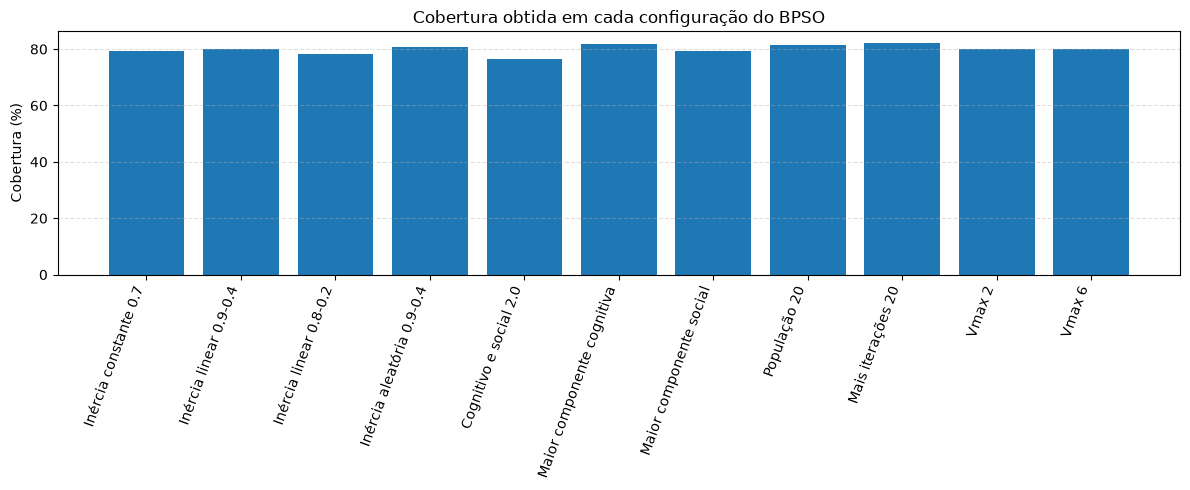

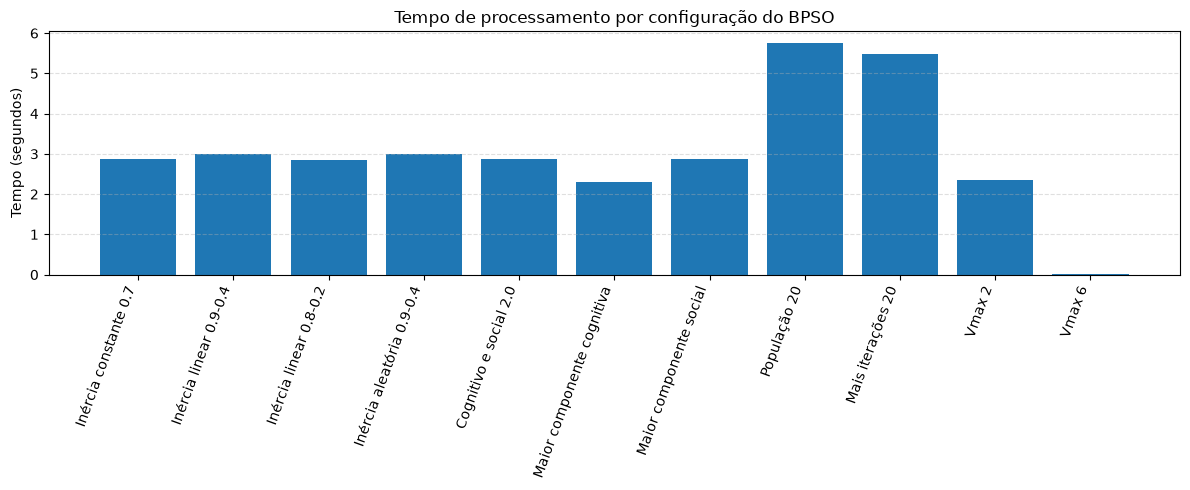

In [9]:
# Tabela comparativa do experimento dos pesos.
display(
    df_pesos[
        ["experimento", "w1_cobertura", "w2_passagens", "w3_sobreposicao",
         "cobertura_pct", "passagens", "sobreposicao_pct", "tempo_segundos"]
    ].sort_values(
        ["cobertura_pct", "sobreposicao_pct"],
        ascending=[False, True]
    )
)

# Tabela comparativa dos hiperparâmetros do BPSO.
display(
    df_bpso[colunas_bpso].sort_values(
        ["score", "cobertura_pct"],
        ascending=[False, False]
    )
)

# Gráfico de cobertura por configuração do BPSO.
plt.figure(figsize=(12, 5))
plt.bar(df_bpso["configuracao"], df_bpso["cobertura_pct"])
plt.xticks(rotation=70, ha="right")
plt.ylabel("Cobertura (%)")
plt.title("Cobertura obtida em cada configuração do BPSO")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

# Gráfico de tempo de processamento.
plt.figure(figsize=(12, 5))
plt.bar(df_bpso["configuracao"], df_bpso["tempo_segundos"])
plt.xticks(rotation=70, ha="right")
plt.ylabel("Tempo (segundos)")
plt.title("Tempo de processamento por configuração do BPSO")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

# Escolha da Solução Final

In [10]:
# Escolhe a configuração de pesos com maior cobertura.
# Em caso de empate, prioriza menor sobreposição e depois menos passagens.
melhor_pesos_linha = df_pesos.sort_values(
    ["cobertura_pct", "sobreposicao_pct", "passagens"],
    ascending=[False, True, True]
).iloc[0]

pesos_finais = (
    melhor_pesos_linha["w1_cobertura"],
    melhor_pesos_linha["w2_passagens"],
    melhor_pesos_linha["w3_sobreposicao"]
)

print(pesos_finais)

# Escolhe os hiperparâmetros com maior score usando PESOS_BASE.
melhor_bpso_linha = df_bpso.sort_values(
    ["score", "cobertura_pct"],
    ascending=[False, False]
).iloc[0]

parametros_finais = {
    "n_particulas": int(melhor_bpso_linha["n_particulas"]),
    "n_iteracoes": int(melhor_bpso_linha["n_iteracoes"]),
    "w_max": float(melhor_bpso_linha["w_max"]),
    "w_min": float(melhor_bpso_linha["w_min"]),
    "tipo_inercia": melhor_bpso_linha["tipo_inercia"],
    "c1": float(melhor_bpso_linha["c1"]),
    "c2": float(melhor_bpso_linha["c2"]),
    "vmax": float(melhor_bpso_linha["vmax"])
}

print("Pesos escolhidos:", pesos_finais)
print("Hiperparâmetros escolhidos:", parametros_finais)

# Executa novamente o BPSO com os parâmetros escolhidos.
resultado_final = executar_bpso(
    pesos=pesos_finais,
    seed=42,
    **parametros_finais
)

print("\nRESULTADO FINAL")
print(f"Score: {resultado_final['melhor_score']:.4f}")
print(f"Cobertura: {resultado_final['cobertura'] * 100:.2f}%")
print(f"Passagens selecionadas: {resultado_final['quantidade']}")
print(f"Sobreposição: {resultado_final['sobreposicao'] * 100:.2f}%")
print(f"Tempo: {resultado_final['tempo_segundos']:.2f} segundos")

(np.float64(50.0), np.float64(0.05), np.float64(0.5))
Pesos escolhidos: (np.float64(50.0), np.float64(0.05), np.float64(0.5))
Hiperparâmetros escolhidos: {'n_particulas': 10, 'n_iteracoes': 20, 'w_max': 0.9, 'w_min': 0.4, 'tipo_inercia': 'linear', 'c1': 1.5, 'c2': 1.5, 'vmax': 4.0}
Iteração 01/20 | Score: 35.9104 | Cobertura: 72.45% | Passagens: 60 | Sobreposição: 42.44%
Iteração 02/20 | Score: 36.7708 | Cobertura: 74.22% | Passagens: 60 | Sobreposição: 47.50%
Iteração 03/20 | Score: 36.9114 | Cobertura: 74.40% | Passagens: 60 | Sobreposição: 37.47%
Iteração 04/20 | Score: 39.7891 | Cobertura: 80.21% | Passagens: 60 | Sobreposição: 43.45%
Iteração 05/20 | Score: 39.7891 | Cobertura: 80.21% | Passagens: 60 | Sobreposição: 43.45%
Iteração 06/20 | Score: 39.7891 | Cobertura: 80.21% | Passagens: 60 | Sobreposição: 43.45%
Iteração 07/20 | Score: 39.7891 | Cobertura: 80.21% | Passagens: 60 | Sobreposição: 43.45%
Iteração 08/20 | Score: 39.7891 | Cobertura: 80.21% | Passagens: 60 | Sobreposiç

# Curva de Convergência da Solução Final

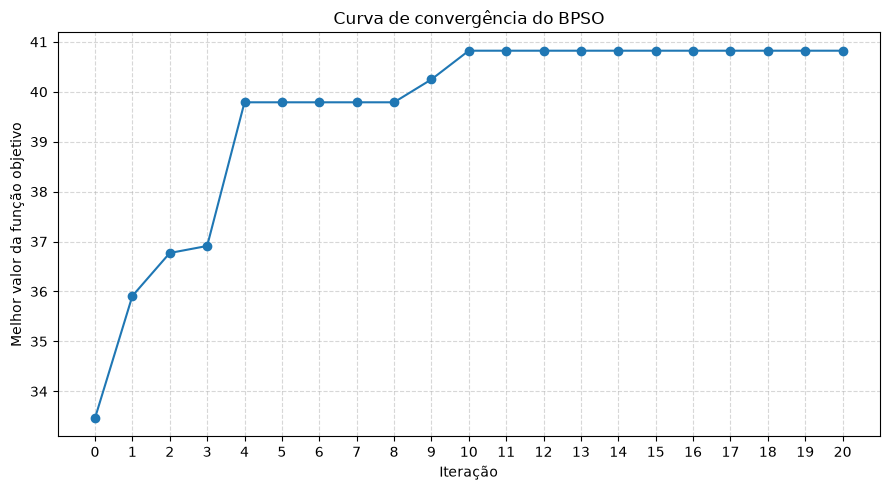

In [11]:
plt.figure(figsize=(9, 5))
plt.plot(
    range(len(resultado_final["historico"])),
    resultado_final["historico"],
    marker="o"
)
plt.xlabel("Iteração")
plt.ylabel("Melhor valor da função objetivo")
plt.title("Curva de convergência do BPSO")
plt.xticks(range(len(resultado_final["historico"])))
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# Mapa da Solução Final

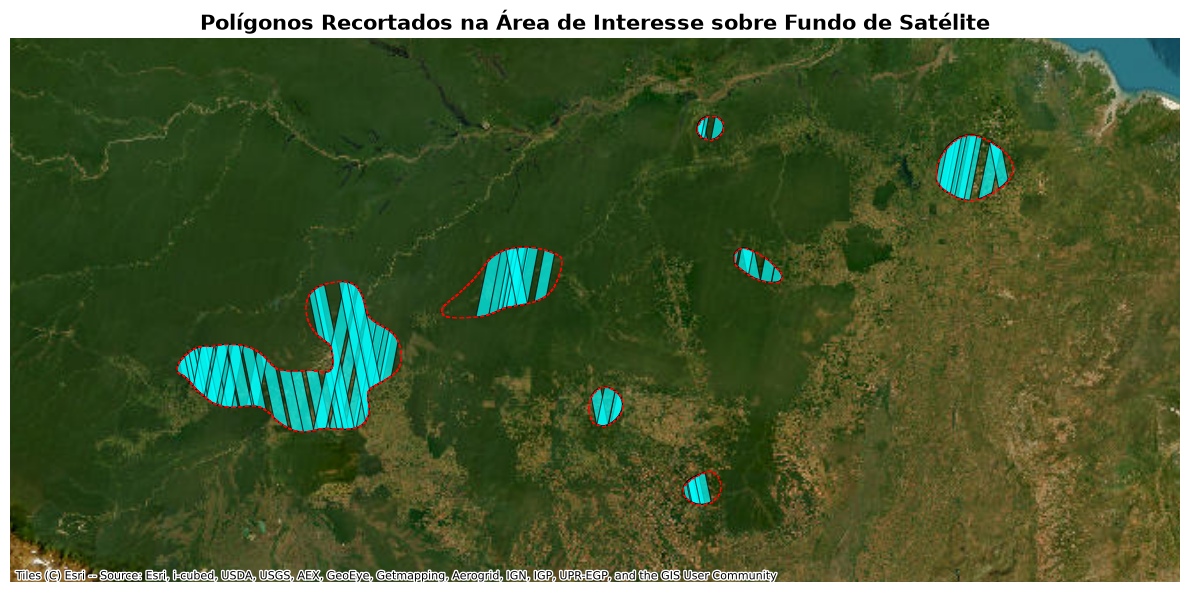

In [12]:
# Recuperar a máscara binária da melhor solução
melhor_mascara = np.asarray(
    resultado_final["melhor_mascara"],
    dtype=bool
)

# Selecionar as passagens correspondentes à melhor solução
passagens_escolhidas = PASSAGENS_SAR.loc[melhor_mascara].copy()

# 2. Recortar o gdf_final usando a geometria da área de interesse
gdf_recortado = passagens_escolhidas.clip(AREAS_INTERESSE)

# 3. Reprojetar ambos para EPSG:3857 (usado pelo mapa-base do contextily)
area_plot = AREAS_INTERESSE.to_crs(epsg=3857)
gdf_recortado_plot = gdf_recortado.to_crs(epsg=3857)

# Criar figura
fig, ax = plt.subplots(figsize=(12, 10))

# Limites da área de interesse
xmin, ymin, xmax, ymax = area_plot.total_bounds

# Adiciona uma margem ao redor da área
dx = xmax - xmin
dy = ymax - ymin

margem_x = dx * 0.20
margem_y = dy * 0.20

ax.set_xlim(xmin - margem_x, xmax + margem_x)
ax.set_ylim(ymin - margem_y, ymax + margem_y)

# Adiciona o fundo de satélite
ctx.add_basemap(
    ax,
    source=ctx.providers.Esri.WorldImagery,
    crs=area_plot.crs
)

# 4. Plotar o gdf final recortado
gdf_recortado_plot.plot(
    ax=ax,
    color='cyan',         # ou use 'column=nome_coluna' caso tenha classes
    alpha=0.7,
    edgecolor='black',
    linewidth=0.8,
    zorder=2,
    label='Polígonos Selecionados'
)

# 5. Desenhar o contorno da área de interesse por cima
area_plot.boundary.plot(
    ax=ax,
    color='red',
    linewidth=1,
    linestyle='--',
    zorder=3,
    label='Área de Interesse'
)

ax.set_title('Polígonos Recortados na Área de Interesse sobre Fundo de Satélite', fontsize=15, fontweight='bold')
ax.set_axis_off()

plt.tight_layout()
plt.savefig('gdf_recortado_amazonia.png', dpi=300, bbox_inches='tight')
plt.show()